# **Build a RAG agent with LangChain**
https://docs.langchain.com/oss/python/langchain/rag

In [1]:
!pip install langchain langchain-text-splitters langchain-community bs4 -q
!pip install -U "langchain[google-genai]" -q
!pip install -U langchain-google-genai -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 32.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 12.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.4/69.4 kB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 976.5 kB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.6/58.6 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 573.3/573.3 kB 19.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.4/166.4 kB 8.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 81.9/81.9 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 37.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━

In [4]:
from google.colab import userdata
GOOGLE_API_KEY = userdata.get('Gemini-API-Key')

In [5]:
import os
os.environ["GOOGLE_API_KEY"] = GOOGLE_API_KEY

In [6]:
from langchain.chat_models import init_chat_model

model = init_chat_model("google_genai:gemini-3.5-flash-lite")

In [7]:
model

ChatGoogleGenerativeAI(metadata={'lc_versions': {'langchain-core': '1.6.10', 'langchain': '1.4.5', 'langchain-google-genai': '4.4.2'}}, profile={'name': 'Gemini 3.5 Flash Lite', 'release_date': '2026-07-21', 'last_updated': '2026-07-21', 'open_weights': False, 'max_input_tokens': 1048576, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': True, 'pdf_inputs': True, 'video_inputs': True, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'image_tool_message': True, 'tool_choice': True, 'reasoning_effort_levels': ['minimal', 'low', 'medium', 'high'], 'reasoning_effort_default': 'minimal'}, google_api_key=SecretStr('**********'), model='gemini-3.5-flash-lite', temperature=None, client=<google.genai.client.Client object at 0x7d486cadea50>, default_metadata=(), model_kwargs=

In [8]:
from langchain_google_genai import GoogleGenerativeAIEmbeddings

embeddings = GoogleGenerativeAIEmbeddings(model="models/gemini-embedding-001")

In [9]:
embeddings

GoogleGenerativeAIEmbeddings(client=<google.genai.client.Client object at 0x7d486c7bbc50>, model='models/gemini-embedding-001', task_type=None, google_api_key=SecretStr('**********'), credentials=None, vertexai=None, project=None, location=None, base_url=None, additional_headers=None, client_args=None, api_version=None, request_options=None, output_dimensionality=None)

In [ ]:
# pip install -U "langchain-core"

In [10]:
from langchain_core.vectorstores import InMemoryVectorStore

vector_store = InMemoryVectorStore(embeddings)

In [11]:
vector_store

# 1. Indexing
<img src='https://mintcdn.com/langchain-5e9cc07a/I6RpA28iE233vhYX/images/rag_indexing.png?w=840&fit=max&auto=format&n=I6RpA28iE233vhYX&q=85&s=1838328a870c7353c42bf1cc2290a779'>

# Loading documents

In [12]:
import bs4
from langchain_community.document_loaders import WebBaseLoader

# Only keep post title, headers, and content from the full HTML.
bs4_strainer = bs4.SoupStrainer(class_=("post-title", "post-header", "post-content"))

loader = WebBaseLoader(
    web_paths=("https://lilianweng.github.io/posts/2023-06-23-agent/",),
    bs_kwargs={"parse_only": bs4_strainer},
)
docs = loader.load()

assert len(docs) == 1

print(f"Total characters: {len(docs[0].page_content)}")

/tmp/ipykernel_2703/726046369.py:2: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import WebBaseLoader


Total characters: 43047


In [13]:
# User-Agent 설정
os.environ["USER_AGENT"] = "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/142.0.0.0 Safari/537.36"

In [14]:
print(docs[0].page_content[:500])



      LLM Powered Autonomous Agents
    
Date: June 23, 2023  |  Estimated Reading Time: 31 min  |  Author: Lilian Weng


Building agents with LLM (large language model) as its core controller is a cool concept. Several proof-of-concepts demos, such as AutoGPT, GPT-Engineer and BabyAGI, serve as inspiring examples. The potentiality of LLM extends beyond generating well-written copies, stories, essays and programs; it can be framed as a powerful general problem solver.
Agent System Overview#
In


In [15]:
docs

[Document(metadata={'source': 'https://lilianweng.github.io/posts/2023-06-23-agent/'}, page_content='\n\n      LLM Powered Autonomous Agents\n    \nDate: June 23, 2023  |  Estimated Reading Time: 31 min  |  Author: Lilian Weng\n\n\nBuilding agents with LLM (large language model) as its core controller is a cool concept. Several proof-of-concepts demos, such as AutoGPT, GPT-Engineer and BabyAGI, serve as inspiring examples. The potentiality of LLM extends beyond generating well-written copies, stories, essays and programs; it can be framed as a powerful general problem solver.\nAgent System Overview#\nIn a LLM-powered autonomous agent system, LLM functions as the agent’s brain, complemented by several key components:\n\nPlanning\n\nSubgoal and decomposition: The agent breaks down large tasks into smaller, manageable subgoals, enabling efficient handling of complex tasks.\nReflection and refinement: The agent can do self-criticism and self-reflection over past actions, learn from mistake

# Splitting documents

In [16]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,  # chunk size (characters)
    chunk_overlap=200,  # chunk overlap (characters)
    add_start_index=True,  # track index in original document
)
all_splits = text_splitter.split_documents(docs)

print(f"Split blog post into {len(all_splits)} sub-documents.")

Split blog post into 63 sub-documents.


# Storing documents

In [17]:
document_ids = vector_store.add_documents(documents=all_splits)

print(document_ids[:3])

['1613c930-3b3b-4635-bf0b-21a28d1299de', '546e818b-43ed-49f2-a149-9ad928798a7a', '2ff6acad-16c5-47b0-8d3d-79e7b69ef453']


In [18]:
document_ids

['1613c930-3b3b-4635-bf0b-21a28d1299de',
 '546e818b-43ed-49f2-a149-9ad928798a7a',
 '2ff6acad-16c5-47b0-8d3d-79e7b69ef453',
 'd89ea6f0-222d-4f9a-8cef-3ab48593a5d9',
 '8a89d640-6795-43ef-81bd-38f5196f1244',
 'c87cf98c-9c19-480a-a4b3-80bab97b1822',
 '7f20a7f3-278a-486a-bec5-f90f719261a4',
 '61950412-da85-47a3-a0cc-c143bca86b73',
 '61bfd207-28e1-4011-ae1b-81b02003804a',
 '04ee7547-88ba-486b-96f6-8edbabe225d1',
 '67b3d157-f5a6-4788-91ea-12cc8766b328',
 '00dada47-ddf7-4a78-8eeb-d20009929c22',
 '6eeb26e5-4f02-46d4-bda2-a7ded7b8cdf6',
 'f15f294a-30e6-4df2-9d68-61ce3dad84f6',
 'd9669a51-ba03-471b-b526-6ace6f151e14',
 '5acd460c-8a28-442d-937b-f7f989ba2209',
 '08a4cc7e-6a28-4b36-9a41-4bb22503fb22',
 '2f2956f1-3458-4e94-80ee-27752d2bf787',
 '712b9c81-0731-4f7e-b686-5ac4c588e983',
 'fb5f6c7c-db96-44cc-893b-275c9dd14e4d',
 'f0e6b89b-7cee-4f00-af45-28f874a9d64b',
 '35779d0a-d9a5-4e30-b063-aced2ea259c5',
 '3044dc29-bc42-45bf-9ae1-7af73536642e',
 'a52f0bcf-cf01-4a16-a51b-1a06a51b6799',
 '65cf78da-7eb3-

# 2. Retrieval and Generation
<img src='https://mintcdn.com/langchain-5e9cc07a/I6RpA28iE233vhYX/images/rag_retrieval_generation.png?w=840&fit=max&auto=format&n=I6RpA28iE233vhYX&q=85&s=67fe2302e241fc24238a5df1cf56573d'>

# RAG agents

In [19]:
from langchain.tools import tool

@tool(response_format="content_and_artifact")
def retrieve_context(query: str):
    """Retrieve information to help answer a query."""
    retrieved_docs = vector_store.similarity_search(query, k=2)
    serialized = "\n\n".join(
        (f"Source: {doc.metadata}\nContent: {doc.page_content}")
        for doc in retrieved_docs
    )
    return serialized, retrieved_docs

In [20]:
from langchain.agents import create_agent

tools = [retrieve_context]
# If desired, specify custom instructions
prompt = (
    "You have access to a tool that retrieves context from a blog post. "
    "Use the tool to help answer user queries."
)
agent = create_agent(model, tools, system_prompt=prompt)

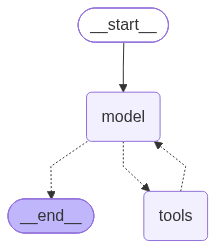

In [21]:
agent

In [22]:
query = (
    "What is the standard method for Task Decomposition?\n\n"
    "Once you get the answer, look up common extensions of that method."
)

for event in agent.stream(
    {"messages": [{"role": "user", "content": query}]},
    stream_mode="values",
):
    event["messages"][-1].pretty_print()

================================ Human Message =================================

What is the standard method for Task Decomposition?

Once you get the answer, look up common extensions of that method.
================================== Ai Message ==================================

[]
Tool Calls:
  retrieve_context (call_1020857)
 Call ID: call_1020857
  Args:
    query: Task Decomposition standard method
================================= Tool Message =================================
Name: retrieve_context

Source: {'source': 'https://lilianweng.github.io/posts/2023-06-23-agent/', 'start_index': 17734}
Content: The AI assistant can parse user input to several tasks: [{"task": task, "id", task_id, "dep": dependency_task_ids, "args": {"text": text, "image": URL, "audio": URL, "video": URL}}]. The "dep" field denotes the id of the previous task which generates a new resource that the current task relies on. A special tag "-task_id" refers to the generated text image, audio and video in 

In [27]:
# Install Gradio library quietly
!pip install gradio -q
import gradio as gr

# Define prediction function for the RAG agent
def predict(message, history):
    # Invoke the RAG agent created in the previous cells
    response = agent.invoke({"messages": [{"role": "user", "content": message}]})
    return response["messages"][-1].content

# Launch Gradio ChatInterface with the mandatory title format and description
demo = gr.ChatInterface(
    fn=predict,
    title="2555047_Solihah Salsabila",
    description="Ask questions about LLM Autonomous Agents!"
)

# Share the interface publicly via a gradio.live URL
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e2fb2ce9bfd900e08e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
